Data folder: /kaggle/input/competitions/domestic-flight-price-prediction-challenge
Train shape: (15589, 12)
Test shape: (3898, 11)
Sample submission shape: (3898, 2)
Skewness of price: 2.7040881851710883
Skewness of log1p(price): 0.7146507007012287


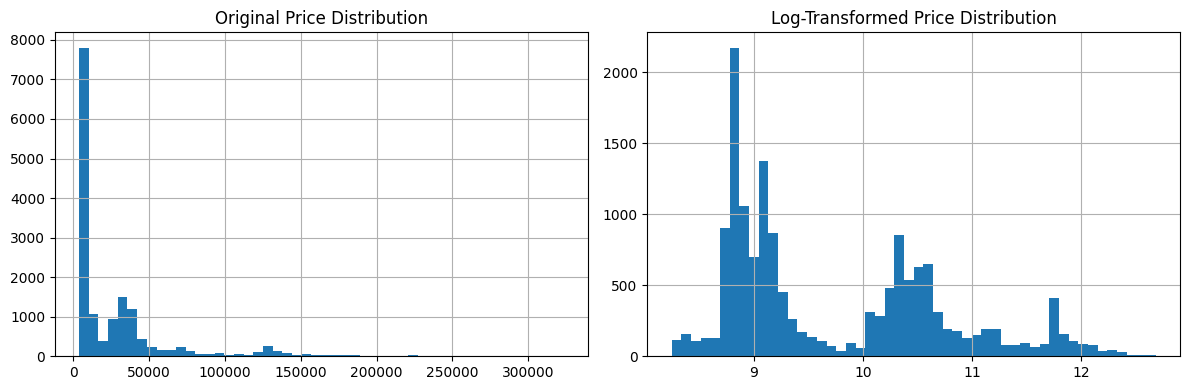

In [1]:

# Goal: Load the datasets and check whether ticket prices are skewed.

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Set a random seed for reproducibility
SEED = 42
np.random.seed(SEED)

# Find the folder containing the competition datasets
base = None

for root, dirs, files in os.walk("/kaggle/input"):
    if "train.csv" in files:
        base = root
        break

if base is None:
    raise FileNotFoundError("Could not find train.csv inside /kaggle/input")

print("Data folder:", base)

# Load the training, test, and sample submission datasets
train = pd.read_csv(os.path.join(base, "train.csv"))
test = pd.read_csv(os.path.join(base, "test.csv"))
sample = pd.read_csv(os.path.join(base, "sample_submission.csv"))

# Check the number of rows and columns
print("Train shape:", train.shape)
print("Test shape:", test.shape)
print("Sample submission shape:", sample.shape)

# Calculate skewness before and after log transformation
print("Skewness of price:", train["price"].skew())
print("Skewness of log1p(price):", np.log1p(train["price"]).skew())

# Compare the original and log-transformed price distributions
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

train["price"].hist(bins=50, ax=ax[0])
ax[0].set_title("Original Price Distribution")

np.log1p(train["price"]).hist(bins=50, ax=ax[1])
ax[1].set_title("Log-Transformed Price Distribution")

plt.tight_layout()
plt.show()


In [2]:

# Goal:
# 1. Check missing values in every column before imputation.
# 2. Fill missing airline and duration values using training data.
# 3. Check missing values in every column after imputation.

# Make copies so the original datasets remain unchanged
train_fe = train.copy()
test_fe = test.copy()


# --------------------------------------------------
# 1. Check missing values before imputation
# --------------------------------------------------

print("Missing values in ORIGINAL training data:")
print(train.isna().sum()[train.isna().sum() > 0].sort_values(ascending=False))

print("\nMissing values in ORIGINAL test data:")
print(test.isna().sum()[test.isna().sum() > 0].sort_values(ascending=False))


# --------------------------------------------------
# 2. Extract useful information from the flight column
# --------------------------------------------------

for df in [train_fe, test_fe]:

    # Extract the flight prefix and flight number
    df["flight_prefix"] = df["flight"].str.split().str[0]
    df["flight_num"] = df["flight"].str.split().str[1].astype(int)

    # Record whether airline and duration were originally missing
    df["airline_missing"] = df["airline"].isna().astype(int)
    df["duration_missing"] = df["duration"].isna().astype(int)


# --------------------------------------------------
# 3. Fill missing airline values using flight prefixes
# --------------------------------------------------

# Learn the most common airline for each prefix from training data
prefix_map = (
    train_fe.dropna(subset=["airline"])
    .groupby("flight_prefix")["airline"]
    .agg(lambda values: values.mode()[0])
)

for df in [train_fe, test_fe]:

    # Fill missing airlines using the learned mapping
    # Use "Unknown" if the prefix has no matching airline
    df["airline"] = (
        df["airline"]
        .fillna(df["flight_prefix"].map(prefix_map))
        .fillna("Unknown")
    )


# --------------------------------------------------
# 4. Fill missing durations using group medians
# --------------------------------------------------

# Try specific groups first, then progressively broader groups
key_levels = [
    ["flight", "source_city", "destination_city", "stops",
     "departure_time", "arrival_time"],

    ["flight", "source_city", "destination_city", "stops"],

    ["source_city", "destination_city", "stops",
     "departure_time", "arrival_time"],

    ["source_city", "destination_city", "stops"],

    ["stops"]
]


def impute_duration(df, reference_data, key_levels):

    df = df.copy()

    for keys in key_levels:

        # Calculate group medians using the reference training data
        median_table = (
            reference_data.dropna(subset=["duration"])
            .groupby(keys)["duration"]
            .median()
            .reset_index(name="median_duration")
        )

        # Find the matching median for each row
        matched_medians = df[keys].merge(
            median_table,
            on=keys,
            how="left"
        )["median_duration"].values

        # Fill only the durations that are still missing
        df["duration"] = df["duration"].fillna(
            pd.Series(matched_medians, index=df.index)
        )

    return df


# Use the original training data to learn duration medians
reference_data = train.copy()

train_fe = impute_duration(train_fe, reference_data, key_levels)
test_fe = impute_duration(test_fe, reference_data, key_levels)


# --------------------------------------------------
# 5. Fill any remaining missing durations
# --------------------------------------------------

# Use the overall median from the original training data
global_median = train["duration"].median()

train_fe["duration"] = train_fe["duration"].fillna(global_median)
test_fe["duration"] = test_fe["duration"].fillna(global_median)


# --------------------------------------------------
# 6. Check missing values after imputation
# --------------------------------------------------

print("\nMissing values in FEATURE-ENGINEERED training data:")
print(train_fe.isna().sum()[train_fe.isna().sum() > 0])

print("\nMissing values in FEATURE-ENGINEERED test data:")
print(test_fe.isna().sum()[test_fe.isna().sum() > 0])


# --------------------------------------------------
# 7. Display final imputation checks
# --------------------------------------------------

print("\nAirline values marked as Unknown:")
print("Train:", (train_fe["airline"] == "Unknown").sum())
print("Test:", (test_fe["airline"] == "Unknown").sum())

print("\nDuration statistics after imputation:")
print(train_fe["duration"].describe())


Missing values in ORIGINAL training data:
duration    3095
airline     3089
dtype: int64

Missing values in ORIGINAL test data:
airline     799
duration    776
dtype: int64

Missing values in FEATURE-ENGINEERED training data:
Series([], dtype: int64)

Missing values in FEATURE-ENGINEERED test data:
Series([], dtype: int64)

Airline values marked as Unknown:
Train: 0
Test: 0

Duration statistics after imputation:
count    15589.000000
mean         4.283041
std          4.152017
min          0.920000
25%          2.250000
50%          2.500000
75%          4.920000
max         38.080000
Name: duration, dtype: float64



--- flight_class ---
              count     mean   median
flight_class                         
Business       6380  60127.0  38546.0
Economy        9209   8818.0   7587.0

--- stops ---
             count      mean    median
stops                                 
two_or_more     66  130463.0  125611.0
one           4558   62782.0   40528.0
zero         10965   15508.0    8883.0

--- airline ---
                       count      mean    median
airline                                         
Weyland Air                8  213388.0  205644.0
Aperture Aviation         31  184405.0  180949.0
Vault-Tec Air             60  183147.0  169353.0
Nakatomi Airlines        407  139510.0  134670.0
Stark Aviation           443  129089.0  130960.0
Virtucon                  95  128235.0  131817.0
Initech Air               11  108003.0  111529.0
Wayne Enterprises Air    228  102476.0  102184.0
Black Mesa Air             7   94334.0  121309.0
Omni Consumer Flights     29   79908.0   95594.0

--- source

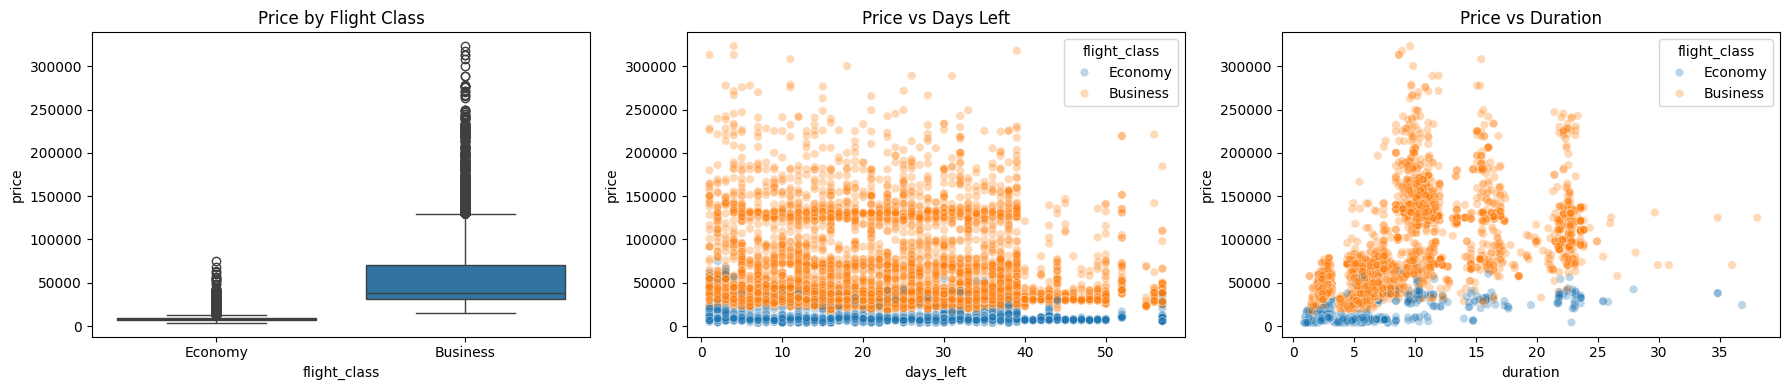


Rows involved in duplicates (features only): 624
Groups where price differs: 35


In [3]:

# Goal:
# Understand how ticket prices vary across features.
# Also check whether identical feature rows have different prices.

import seaborn as sns

# Work on a copy of the feature-engineered training data
df = train_fe.copy()


# --------------------------------------------------
# 1. Compare prices across categorical features
# --------------------------------------------------

categorical_features = [
    "flight_class",
    "stops",
    "airline",
    "source_city",
    "destination_city",
    "departure_time",
    "arrival_time"
]

for col in categorical_features:

    print(f"\n--- {col} ---")

    # Calculate the number of flights, average price, and median price
    price_summary = (
        df.groupby(col)["price"]
        .agg(["count", "mean", "median"])
        .sort_values("mean", ascending=False)
        .round(0)
    )

    # Display the 10 groups with the highest average prices
    print(price_summary.head(10))


# --------------------------------------------------
# 2. Check correlations between numerical features and price
# --------------------------------------------------

numeric_features = ["duration", "days_left", "price"]

print("\nCorrelation with price (overall):")
print(df[numeric_features].corr()["price"].round(3))

# Check correlations separately for Economy and Business class
for flight_class in ["Economy", "Business"]:

    class_data = df[df["flight_class"] == flight_class]

    print(f"\nCorrelation with price within {flight_class}:")

    correlations = class_data[numeric_features].corr()["price"].round(3)

    print(correlations.to_dict())


# --------------------------------------------------
# 3. Visualize price relationships
# --------------------------------------------------

fig, ax = plt.subplots(1, 3, figsize=(18, 4))

# Compare ticket prices across flight classes
sns.boxplot(data=df, x="flight_class", y="price", ax=ax[0])
ax[0].set_title("Price by Flight Class")

# See how prices vary with the number of days before departure
sns.scatterplot(
    data=df,
    x="days_left",
    y="price",
    hue="flight_class",
    alpha=0.3,
    ax=ax[1]
)
ax[1].set_title("Price vs Days Left")

# See how prices vary with flight duration
sns.scatterplot(
    data=df,
    x="duration",
    y="price",
    hue="flight_class",
    alpha=0.3,
    ax=ax[2]
)
ax[2].set_title("Price vs Duration")

plt.tight_layout()
plt.show()


# --------------------------------------------------
# 4. Check duplicate rows and their prices
# --------------------------------------------------

# Use the original training data for this check.
# Ignore id and price when comparing flight features.
feature_columns = [
    col for col in train.columns
    if col not in ["id", "price"]
]

# Find all rows whose feature values appear more than once
duplicates = train[
    train.duplicated(subset=feature_columns, keep=False)
]

print("\nRows involved in duplicates (features only):", len(duplicates))

# Count feature groups that have more than one distinct price
different_price_groups = (
    duplicates.groupby(feature_columns, dropna=False)["price"]
    .nunique()
    .gt(1)
    .sum()
)

print("Groups where price differs:", different_price_groups)


In [4]:

# Ignore id and price when comparing input features
feature_columns = [
    col for col in train.columns
    if col not in ["id", "price"]
]

# Count rows with identical features and identical prices
exact_duplicates = train.duplicated(
    subset=feature_columns + ["price"]
).sum()

# Count rows with identical features, regardless of price
feature_duplicates = train.duplicated(
    subset=feature_columns
).sum()

print("Duplicate rows with same features AND price:", exact_duplicates)
print("Duplicate rows with same features, regardless of price:", feature_duplicates)

# Calculate how many redundant rows have the same features and price
# (The second count includes all repeated feature combinations.)
print("Additional rows with repeated feature combinations:", feature_duplicates)


Duplicate rows with same features AND price: 279
Duplicate rows with same features, regardless of price: 314
Additional rows with repeated feature combinations: 314


In [5]:

# Goal:
# Split the data into training and validation sets.
# Build reusable preprocessing and evaluation functions.
# Compare Linear Regression with and without log-transformed prices.

from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error


# --------------------------------------------------
# 1. Separate input features (X) and target (y)
# --------------------------------------------------

# Exclude the target, row ID, and flight identifier columns.
drop_cols = ["id", "price", "flight", "flight_prefix", "flight_num"]

X = train_fe.drop(columns=drop_cols)
y = train_fe["price"]


# --------------------------------------------------
# 2. Split into training and validation sets
# --------------------------------------------------

# Use 80% of the data for training and 20% for validation.
X_tr, X_val, y_tr, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=SEED
)

print("Training features:", X_tr.shape)
print("Validation features:", X_val.shape)


# --------------------------------------------------
# 3. Identify categorical and numerical columns
# --------------------------------------------------

cat_cols = X.select_dtypes(
    include=["object", "string"]
).columns.tolist()

num_cols = [
    col for col in X.columns
    if col not in cat_cols
]

print("\nCategorical columns:", cat_cols)
print("Numerical columns:", num_cols)


# --------------------------------------------------
# 4. Create a reusable preprocessing function
# --------------------------------------------------

def make_preprocessor(cat_cols, num_cols):

    # Categorical features:
    # Fill missing values with the most frequent category.
    # Then convert categories into numerical columns.
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    # Numerical features:
    # Fill missing values with the median.
    # Then standardize numerical values.
    numerical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    # Apply the appropriate preprocessing to each column type.
    preprocessor = ColumnTransformer([
        ("cat", categorical_pipeline, cat_cols),
        ("num", numerical_pipeline, num_cols)
    ])

    return preprocessor


# --------------------------------------------------
# 5. Set up five-fold cross-validation
# --------------------------------------------------

kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)


# --------------------------------------------------
# 6. Create a reusable model evaluation function
# --------------------------------------------------

def evaluate(model, name, log_target=False):

    # Optionally transform prices using log(1 + price).
    # Predictions are converted back to the original price scale.
    if log_target:
        estimator = TransformedTargetRegressor(
            regressor=model,
            func=np.log1p,
            inverse_func=np.expm1
        )
    else:
        estimator = model

    # Train on the training split
    estimator.fit(X_tr, y_tr)

    # Predict on both training and validation data
    train_predictions = estimator.predict(X_tr)
    val_predictions = estimator.predict(X_val)

    # Perform five-fold cross-validation.
    # Preprocessing is refitted separately within every fold.
    cv_scores = cross_validate(
        estimator,
        X,
        y,
        cv=kf,
        scoring="r2",
        return_train_score=True
    )

    # Calculate R-squared scores
    train_r2 = r2_score(y_tr, train_predictions)
    val_r2 = r2_score(y_val, val_predictions)

    # Store all metrics in a dictionary
    model_results = {
        "model": name,
        "log_target": log_target,

        "train_R2": train_r2,
        "val_R2": val_r2,
        "R2_gap": train_r2 - val_r2,

        "train_RMSE": np.sqrt(
            mean_squared_error(y_tr, train_predictions)
        ),
        "val_RMSE": np.sqrt(
            mean_squared_error(y_val, val_predictions)
        ),

        "train_MAE": mean_absolute_error(y_tr, train_predictions),
        "val_MAE": mean_absolute_error(y_val, val_predictions),

        "cv_train_R2": cv_scores["train_score"].mean(),
        "cv_val_R2": cv_scores["test_score"].mean(),
        "cv_val_std": cv_scores["test_score"].std()
    }

    return model_results, estimator


# --------------------------------------------------
# 7. Evaluate Linear Regression with both target options
# --------------------------------------------------

results = []

for log_target in [False, True]:

    # Create a fresh preprocessing and Linear Regression pipeline
    pipeline = Pipeline([
        ("prep", make_preprocessor(cat_cols, num_cols)),
        ("model", LinearRegression())
    ])

    # Evaluate the model
    model_results, fitted_model = evaluate(
        pipeline,
        "LinearRegression (baseline)",
        log_target=log_target
    )

    results.append(model_results)


# --------------------------------------------------
# 8. Display the results
# --------------------------------------------------

pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 30)

results_df = pd.DataFrame(results)

print(results_df.round(4))


Training features: (12471, 11)
Validation features: (3118, 11)

Categorical columns: ['airline', 'source_city', 'departure_time', 'stops', 'arrival_time', 'destination_city', 'flight_class']
Numerical columns: ['duration', 'days_left', 'airline_missing', 'duration_missing']
                         model  log_target  train_R2  val_R2  R2_gap  train_RMSE    val_RMSE  train_MAE    val_MAE  cv_train_R2  cv_val_R2  cv_val_std
0  LinearRegression (baseline)       False    0.8589  0.8698 -0.0109  14842.7676  13547.6363  7230.3048  6830.3493       0.8613     0.8591      0.0133
1  LinearRegression (baseline)        True    0.8437  0.8535 -0.0099  15621.6158  14367.8963  6135.7178  5733.4519       0.8442     0.8412      0.0094


In [6]:

# Goal:
# Create new features that may improve price predictions.
# Compare Linear Regression with and without log-transformed prices.
# Compare the results against our original baseline.

# --------------------------------------------------
# 1. Create additional features
# --------------------------------------------------

def add_features(df):

    # Make a copy so the original dataset is not modified
    d = df.copy()

    # Convert flight class into a numerical indicator
    # Business = 1, Economy = 0
    d["is_business"] = (d["flight_class"] == "Business").astype(int)

    # Combine related categorical features
    d["route"] = d["source_city"] + "_" + d["destination_city"]
    d["airline_class"] = d["airline"] + "_" + d["flight_class"]
    d["stops_class"] = d["stops"] + "_" + d["flight_class"]

    # Add nonlinear transformations of duration
    d["duration_sq"] = d["duration"] ** 2
    d["duration_log"] = np.log1p(d["duration"])

    # Allow duration and days_left to have different effects for Business
    d["biz_duration"] = d["is_business"] * d["duration"]
    d["biz_duration_sq"] = d["is_business"] * d["duration_sq"]
    d["biz_days_left"] = d["is_business"] * d["days_left"]

    # Group days_left into intervals
    # Example intervals: 1-2 days, 2-5 days, and so on
    d["days_bucket"] = pd.cut(
        d["days_left"],
        bins=[0, 2, 5, 10, 20, 30, 40, 100],
        labels=False
    ).astype(str)

    # Combine the booking-time bucket with flight class
    d["bucket_class"] = d["days_bucket"] + "_" + d["flight_class"]

    return d


# Apply the same feature engineering to training and test data
train_fe2 = add_features(train_fe)
test_fe2 = add_features(test_fe)


# --------------------------------------------------
# 2. Prepare X and y using the engineered dataset
# --------------------------------------------------

# Exclude identifiers and the target from model inputs
drop_cols = ["id", "price", "flight", "flight_prefix", "flight_num"]

X = train_fe2.drop(columns=drop_cols)
y = train_fe2["price"]


# --------------------------------------------------
# 3. Recreate the same train-validation split
# --------------------------------------------------

# Keep the same seed and split ratio for a fair comparison
X_tr, X_val, y_tr, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=SEED
)


# --------------------------------------------------
# 4. Identify categorical and numerical features
# --------------------------------------------------

cat_cols = X.select_dtypes(
    include=["object", "string"]
).columns.tolist()

num_cols = [
    col for col in X.columns
    if col not in cat_cols
]

print("Categorical features:", cat_cols)
print("Numerical features:", num_cols)


# --------------------------------------------------
# 5. Train and evaluate both Linear Regression models
# --------------------------------------------------

results2 = []

for log_target in [False, True]:

    # Build the preprocessing and regression pipeline
    pipeline = Pipeline([
        ("prep", make_preprocessor(cat_cols, num_cols)),
        ("model", LinearRegression())
    ])

    # Use the existing evaluation function
    model_results, fitted_model = evaluate(
        pipeline,
        "LinearRegression + engineered feats",
        log_target=log_target
    )

    results2.append(model_results)


# --------------------------------------------------
# 6. Compare baseline and engineered-feature results
# --------------------------------------------------

comparison_columns = [
    "model",
    "log_target",
    "train_R2",
    "val_R2",
    "R2_gap",
    "train_RMSE",
    "val_RMSE",
    "train_MAE",
    "val_MAE",
    "cv_train_R2",
    "cv_val_R2"
]

comparison = pd.DataFrame(results + results2)

print("\nBaseline vs engineered features:")
print(
    comparison[comparison_columns]
    .round(4)
    .to_string(index=False)
)


Categorical features: ['airline', 'source_city', 'departure_time', 'stops', 'arrival_time', 'destination_city', 'flight_class', 'route', 'airline_class', 'stops_class', 'days_bucket', 'bucket_class']
Numerical features: ['duration', 'days_left', 'airline_missing', 'duration_missing', 'is_business', 'duration_sq', 'duration_log', 'biz_duration', 'biz_duration_sq', 'biz_days_left']

Baseline vs engineered features:
                              model  log_target  train_R2  val_R2  R2_gap  train_RMSE   val_RMSE  train_MAE   val_MAE  cv_train_R2  cv_val_R2
        LinearRegression (baseline)       False    0.8589  0.8698 -0.0109  14842.7676 13547.6363  7230.3048 6830.3493       0.8613     0.8591
        LinearRegression (baseline)        True    0.8437  0.8535 -0.0099  15621.6158 14367.8963  6135.7178 5733.4519       0.8442     0.8412
LinearRegression + engineered feats       False    0.9005  0.8993  0.0012  12462.6370 11911.2822  5621.1709 5464.8573       0.9009     0.8977
LinearRegressio

In [7]:

# Goal:
# Compare Ridge, Lasso, and ElasticNet using a smaller
# hyperparameter search to reduce execution time.

from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.model_selection import GridSearchCV
from sklearn.compose import TransformedTargetRegressor


# --------------------------------------------------
# 1. Define the models and their hyperparameters
# --------------------------------------------------

searches = {
    "Ridge": (
        Ridge(),
        {
            "regressor__model__alpha": [1, 10, 100]
        }
    ),

    "Lasso": (
        Lasso(max_iter=20000, tol=1e-3),
        {
            "regressor__model__alpha": [0.001, 0.01, 0.1]
        }
    ),

    "ElasticNet": (
        ElasticNet(max_iter=20000, tol=1e-3),
        {
            "regressor__model__alpha": [0.001, 0.01, 0.1],
            "regressor__model__l1_ratio": [0.2, 0.8]
        }
    )
}


# --------------------------------------------------
# 2. Create a function to tune and evaluate a model
# --------------------------------------------------

def run_search(model, grid, name):

    # Preprocess the features and train the selected model
    pipeline = Pipeline([
        ("prep", make_preprocessor(cat_cols, num_cols)),
        ("model", model)
    ])

    # Standardize the target during training and convert
    # predictions back to the original price scale
    estimator = TransformedTargetRegressor(
        regressor=pipeline,
        transformer=StandardScaler()
    )

    # Use three-fold CV to reduce the number of model fits
    grid_search = GridSearchCV(
        estimator=estimator,
        param_grid=grid,
        cv=3,
        scoring="r2",
        n_jobs=1,
        verbose=1
    )

    # Search for the best hyperparameters using training data only
    grid_search.fit(X_tr, y_tr)

    # Predict on training and validation data using the best model
    train_predictions = grid_search.predict(X_tr)
    val_predictions = grid_search.predict(X_val)

    # Store the best model's results
    return {
        "model": name,
        "best_params": grid_search.best_params_,
        "best_CV_R2": grid_search.best_score_,
        "train_R2": r2_score(y_tr, train_predictions),
        "val_R2": r2_score(y_val, val_predictions),
        "R2_gap": (
            r2_score(y_tr, train_predictions)
            - r2_score(y_val, val_predictions)
        ),
        "val_RMSE": np.sqrt(
            mean_squared_error(y_val, val_predictions)
        )
    }


# --------------------------------------------------
# 3. Run the smaller hyperparameter searches
# --------------------------------------------------

reg_results = []

for name, (model, grid) in searches.items():

    print(f"\nTuning {name}...")

    result = run_search(model, grid, name)
    reg_results.append(result)


# --------------------------------------------------
# 4. Compare the results
# --------------------------------------------------

results_reg_df = pd.DataFrame(reg_results)

print("\nRegularized Regression Results:")
print(results_reg_df.round(4).to_string(index=False))



Tuning Ridge...
Fitting 3 folds for each of 3 candidates, totalling 9 fits

Tuning Lasso...
Fitting 3 folds for each of 3 candidates, totalling 9 fits

Tuning ElasticNet...
Fitting 3 folds for each of 6 candidates, totalling 18 fits

Regularized Regression Results:
     model                                                           best_params  best_CV_R2  train_R2  val_R2  R2_gap   val_RMSE
     Ridge                                        {'regressor__model__alpha': 1}      0.8972    0.9004  0.8995  0.0009 11900.6454
     Lasso                                    {'regressor__model__alpha': 0.001}      0.8896    0.8925  0.8921  0.0004 12332.3994
ElasticNet {'regressor__model__alpha': 0.001, 'regressor__model__l1_ratio': 0.2}      0.8941    0.8973  0.8975 -0.0003 12017.0184


In [8]:

# Goal:
# Compare Ridge Regression with and without the flight code.
# Use the same engineered features and validation split.

from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV

# --------------------------------------------------
# 1. Prepare data WITHOUT flight
# --------------------------------------------------

X_no_flight = X.copy()

# --------------------------------------------------
# 2. Prepare data WITH flight
# --------------------------------------------------

X_with_flight = X.copy()
X_with_flight["flight"] = train_fe2["flight"]

# Keep exactly the same training and validation rows
X_tr_flight = X_with_flight.loc[X_tr.index]
X_val_flight = X_with_flight.loc[X_val.index]

# Add flight to the categorical columns
cat_cols_flight = cat_cols + ["flight"]


# --------------------------------------------------
# 3. Tune Ridge and evaluate either feature set
# --------------------------------------------------

def compare_ridge(X_train, X_valid, categorical_cols, name):

    pipeline = Pipeline([
        ("prep", make_preprocessor(categorical_cols, num_cols)),
        ("model", Ridge())
    ])

    # Try several regularization strengths using training data only
    search = GridSearchCV(
        pipeline,
        param_grid={"model__alpha": [0.1, 1, 10, 30]},
        cv=3,
        scoring="r2",
        n_jobs=1
    )

    search.fit(X_train, y_tr)

    # Evaluate the selected model on training and validation data
    train_pred = search.predict(X_train)
    val_pred = search.predict(X_valid)

    return {
        "features": name,
        "best_alpha": search.best_params_["model__alpha"],
        "CV_R2": search.best_score_,
        "train_R2": r2_score(y_tr, train_pred),
        "val_R2": r2_score(y_val, val_pred),
        "val_RMSE": np.sqrt(mean_squared_error(y_val, val_pred)),
        "val_MAE": mean_absolute_error(y_val, val_pred)
    }


# --------------------------------------------------
# 4. Compare both experiments
# --------------------------------------------------

flight_results = []

flight_results.append(
    compare_ridge(
        X_tr, X_val, cat_cols,
        "Without flight"
    )
)

flight_results.append(
    compare_ridge(
        X_tr_flight, X_val_flight, cat_cols_flight,
        "With flight"
    )
)

print(pd.DataFrame(flight_results).round(4).to_string(index=False))


      features  best_alpha  CV_R2  train_R2  val_R2   val_RMSE   val_MAE
Without flight           1 0.8972    0.9004  0.8995 11900.6915 5468.6479
   With flight           1 0.9155    0.9268  0.9156 10909.5197 4700.7707


 degree       model  train_R2  val_R2     gap   val_RMSE
      1   LinearReg    0.8949  0.8944  0.0006 12201.8025
      1 Ridge(a=10)    0.8933  0.8939 -0.0006 12228.7040
      2   LinearReg    0.8977  0.8969  0.0008 12055.0423
      2 Ridge(a=10)    0.8962  0.8967 -0.0005 12067.6038
      3   LinearReg    0.9010  0.8985  0.0025 11963.1342
      3 Ridge(a=10)    0.8988  0.8986  0.0003 11956.8240
      4   LinearReg    0.9027  0.9003  0.0025 11854.7687
      4 Ridge(a=10)    0.8997  0.8983  0.0014 11971.2951
      5   LinearReg    0.9030  0.8998  0.0032 11881.8730
      5 Ridge(a=10)    0.9000  0.8986  0.0013 11952.8802
      6   LinearReg    0.9038  0.8991  0.0047 11924.8795
      6 Ridge(a=10)    0.9004  0.8991  0.0014 11926.7981


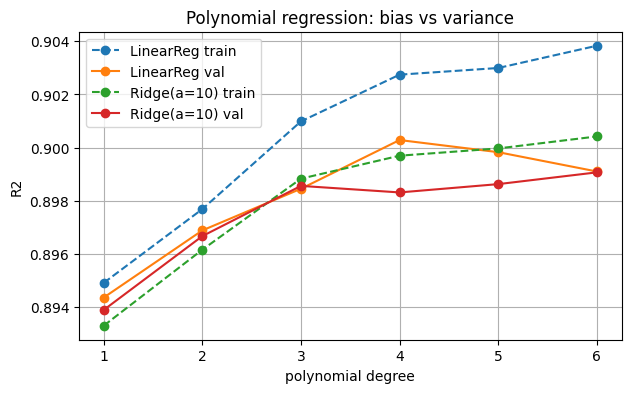

In [11]:
# GOAL: Add polynomial terms (degree 1-6) on duration, days_left and is_business (this also creates class interactions), and compare plain Linear Regression vs Ridge to see where it overfits.

from sklearn.preprocessing import PolynomialFeatures

poly_cols = ["duration", "days_left", "is_business"]
flag_cols = ["airline_missing", "duration_missing"]

def make_poly_prep(degree):
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
        ("poly", Pipeline([("poly", PolynomialFeatures(degree=degree, include_bias=False)),
                           ("sc", StandardScaler())]), poly_cols),
        ("flags", StandardScaler(), flag_cols),
    ])

rows = []
for deg in [1, 2, 3, 4, 5, 6]:
    for name, reg in [("LinearReg", LinearRegression()), ("Ridge(a=10)", Ridge(alpha=10, random_state=SEED))]:
        pipe = Pipeline([("prep", make_poly_prep(deg)), ("model", reg)])
        pipe.fit(X_tr, y_tr)
        p_tr, p_val = pipe.predict(X_tr), pipe.predict(X_val)
        rows.append({"degree": deg, "model": name,
                     "train_R2": r2_score(y_tr, p_tr), "val_R2": r2_score(y_val, p_val),
                     "gap": r2_score(y_tr, p_tr) - r2_score(y_val, p_val),
                     "val_RMSE": np.sqrt(mean_squared_error(y_val, p_val))})

poly_curve = pd.DataFrame(rows)
print(poly_curve.round(4).to_string(index=False))

plt.figure(figsize=(7, 4))
for name in ["LinearReg", "Ridge(a=10)"]:
    s = poly_curve[poly_curve.model == name]
    plt.plot(s["degree"], s["train_R2"], marker="o", linestyle="--", label=f"{name} train")
    plt.plot(s["degree"], s["val_R2"], marker="o", label=f"{name} val")
plt.xlabel("polynomial degree"); plt.ylabel("R2"); plt.title("Polynomial regression: bias vs variance")
plt.legend(); plt.grid(True); plt.show()

max_depth  train_R2  val_R2     gap   val_RMSE
        2    0.8151  0.8200 -0.0049 15927.4635
        4    0.8750  0.8798 -0.0048 13017.0045
        6    0.9063  0.8974  0.0089 12023.9684
        8    0.9260  0.9184  0.0076 10721.0324
       10    0.9441  0.9254  0.0186 10250.6129
       12    0.9540  0.9123  0.0417 11114.6951
       15    0.9669  0.9041  0.0628 11627.8687
       20    0.9726  0.9024  0.0702 11726.7825
       25    0.9731  0.9011  0.0721 11808.9047
     None    0.9732  0.9037  0.0694 11647.6142


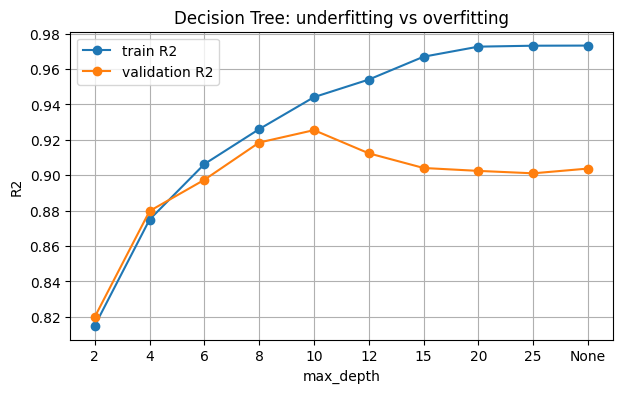

In [12]:
# GOAL: Train decision trees of increasing depth and compare train vs validation R2 to find where the tree stops underfitting and starts overfitting.

from sklearn.tree import DecisionTreeRegressor

# Step 1: convert categories to numbers (one-hot) the same way as before.
# Fit on the TRAIN split only, then apply the same transformation to validation.
prep = make_preprocessor(cat_cols, num_cols)
X_tr_t = prep.fit_transform(X_tr)
X_val_t = prep.transform(X_val)

# Step 2: depths to try. Small depth = simple tree, large depth = complex tree.
depths = [2, 4, 6, 8, 10, 12, 15, 20, 25, None]   # None = grow until leaves are pure

results_tree = []
for d in depths:
    # Step 3: build and train one tree with this depth
    # min_samples_leaf=3 stops leaves from holding just 1 row (reduces memorising)
    tree = DecisionTreeRegressor(max_depth=d, min_samples_leaf=3, random_state=SEED)
    tree.fit(X_tr_t, y_tr)

    # Step 4: predict on both train and validation data
    pred_tr = tree.predict(X_tr_t)
    pred_val = tree.predict(X_val_t)

    # Step 5: record the scores
    results_tree.append({
        "max_depth": str(d),
        "train_R2": r2_score(y_tr, pred_tr),
        "val_R2": r2_score(y_val, pred_val),
        "gap": r2_score(y_tr, pred_tr) - r2_score(y_val, pred_val),
        "val_RMSE": np.sqrt(mean_squared_error(y_val, pred_val)),
    })

# Step 6: show the table
tree_df = pd.DataFrame(results_tree)
print(tree_df.round(4).to_string(index=False))

# Step 7: plot train vs validation R2 against depth
plt.figure(figsize=(7, 4))
plt.plot(tree_df["max_depth"], tree_df["train_R2"], marker="o", label="train R2")
plt.plot(tree_df["max_depth"], tree_df["val_R2"], marker="o", label="validation R2")
plt.xlabel("max_depth")
plt.ylabel("R2")
plt.title("Decision Tree: underfitting vs overfitting")
plt.legend()
plt.grid(True)
plt.show()

In [13]:
# GOAL: Find the best decision tree settings (max_depth, min_samples_leaf, min_samples_split) using 5-fold cross-validation on the training split.

from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import GridSearchCV

# Pipeline = one-hot encoding + tree.
# Putting the encoder inside the pipeline means it is re-fit on each CV fold's training part only (no leakage).
tree_pipe = Pipeline([
    ("prep", make_preprocessor(cat_cols, num_cols)),
    ("model", DecisionTreeRegressor(random_state=SEED)),
])

# Settings to try
param_grid = {
    "model__max_depth": [8, 9, 10, 11, 12],          # around the best depth we saw (10)
    "model__min_samples_leaf": [1, 3, 5, 10, 20],    # bigger = smoother tree, less overfitting
    "model__min_samples_split": [2, 10],             # min rows needed to split a node
}

# Try every combination, score each with 5-fold CV R2
grid = GridSearchCV(tree_pipe, param_grid, cv=kf, scoring="r2", n_jobs=-1)
grid.fit(X_tr, y_tr)

# Show the 5 best combinations
cv_table = pd.DataFrame(grid.cv_results_)
cv_table = cv_table[["param_model__max_depth", "param_model__min_samples_leaf",
                     "param_model__min_samples_split", "mean_test_score", "std_test_score"]]
print("Top 5 settings by CV R2:")
print(cv_table.sort_values("mean_test_score", ascending=False).head(5).round(4).to_string(index=False))

# Evaluate the best tree on train and validation data
best_tree = grid.best_estimator_
pred_tr = best_tree.predict(X_tr)
pred_val = best_tree.predict(X_val)

print("\nBest settings:", grid.best_params_)
print("Train R2 :", round(r2_score(y_tr, pred_tr), 4))
print("Val   R2 :", round(r2_score(y_val, pred_val), 4))
print("Gap      :", round(r2_score(y_tr, pred_tr) - r2_score(y_val, pred_val), 4))
print("Val RMSE :", round(np.sqrt(mean_squared_error(y_val, pred_val)), 2))
print("Val MAE  :", round(mean_absolute_error(y_val, pred_val), 2))

Top 5 settings by CV R2:
 param_model__max_depth  param_model__min_samples_leaf  param_model__min_samples_split  mean_test_score  std_test_score
                     10                              3                              10           0.9049          0.0086
                     11                              3                              10           0.9041          0.0089
                      8                              3                              10           0.9040          0.0113
                      9                              3                              10           0.9037          0.0124
                      8                              1                              10           0.9035          0.0136

Best settings: {'model__max_depth': 10, 'model__min_samples_leaf': 3, 'model__min_samples_split': 10}
Train R2 : 0.9435
Val   R2 : 0.9245
Gap      : 0.019
Val RMSE : 10316.12
Val MAE  : 3886.51


In [14]:
# GOAL: Find which groups of flights (class, stops, airline) cause most of the tree's error on the validation set, so we know what to improve.

# Step 1: put validation data, true price and predicted price in one table
val_df = X_val.copy()
val_df["price"] = y_val.values
val_df["pred"] = best_tree.predict(X_val)

# Step 2: error of each row
val_df["abs_err"] = (val_df["price"] - val_df["pred"]).abs()
val_df["sq_err"] = (val_df["price"] - val_df["pred"]) ** 2

# Step 3: for each group, show how many rows, average error, and its share of the total squared error
def error_by(col):
    g = val_df.groupby(col).agg(rows=("price", "size"),
                                mean_price=("price", "mean"),
                                MAE=("abs_err", "mean"),
                                sq_err_sum=("sq_err", "sum"))
    g["share_of_total_error_%"] = 100 * g["sq_err_sum"] / val_df["sq_err"].sum()
    return g.drop(columns="sq_err_sum").sort_values("share_of_total_error_%", ascending=False).round(1)

for col in ["flight_class", "stops", "airline"]:
    print(f"\n--- error by {col} ---")
    print(error_by(col).head(8).to_string())

# Step 4: R2 inside each class separately
print()
for c, g in val_df.groupby("flight_class"):
    print(c, "R2:", round(r2_score(g["price"], g["pred"]), 4))


--- error by flight_class ---
              rows  mean_price     MAE  share_of_total_error_%
flight_class                                                  
Business      1249     58957.0  7869.3                    96.6
Economy       1869      8807.8  1224.9                     3.4

--- error by stops ---
             rows  mean_price      MAE  share_of_total_error_%
stops                                                         
one           909     60080.0   8087.2                    85.1
zero         2199     15506.7   2068.6                    11.4
two_or_more    10    138723.7  21816.8                     3.5

--- error by airline ---
                       rows  mean_price      MAE  share_of_total_error_%
airline                                                                 
Nakatomi Airlines        74    137901.9  35007.4                    49.7
Wayfarer Aviation      1233     24007.5   3336.3                    15.8
Stark Aviation           94    127344.6  12104.1            

In [15]:
# GOAL: Test whether adding the 'flight' code, the flight number, or training separate trees per class improves the tuned decision tree (all use depth=10, min_samples_leaf=3, min_samples_split=10).

from sklearn.model_selection import cross_val_score

# Step 1: the tuned tree settings from the grid search
def make_tree():
    return DecisionTreeRegressor(max_depth=10, min_samples_leaf=3, min_samples_split=10, random_state=SEED)

# Step 2: extra columns we had dropped earlier (flight code and flight number)
X_ext = X.copy()
X_ext["flight"] = train_fe2["flight"].values
X_ext["flight_num"] = train_fe2["flight_num"].values

# Step 3: helper that scores one variant (train R2, validation R2, and 5-fold CV R2 on the train split)
def score_variant(label, Xtr_, Xval_, cat_, num_):
    pipe = Pipeline([("prep", make_preprocessor(cat_, num_)), ("model", make_tree())])
    cv = cross_val_score(pipe, Xtr_, y_tr, cv=kf, scoring="r2")
    pipe.fit(Xtr_, y_tr)
    p_tr, p_val = pipe.predict(Xtr_), pipe.predict(Xval_)
    return {"variant": label,
            "train_R2": r2_score(y_tr, p_tr),
            "val_R2": r2_score(y_val, p_val),
            "cv_R2": cv.mean(),
            "val_RMSE": np.sqrt(mean_squared_error(y_val, p_val))}

variants = []

# Variant A: current tree (no flight info)
variants.append(score_variant("A: current features", X_tr, X_val, cat_cols, num_cols))

# Variant B: add the flight code as a categorical feature
variants.append(score_variant("B: + flight code (one-hot)",
                              X_ext.loc[X_tr.index], X_ext.loc[X_val.index],
                              cat_cols + ["flight"], num_cols))

# Variant C: add the flight number as a plain numeric feature
variants.append(score_variant("C: + flight number (numeric)",
                              X_ext.loc[X_tr.index], X_ext.loc[X_val.index],
                              cat_cols, num_cols + ["flight_num"]))

# Variant D: one tree for Economy and one tree for Business
val_pred = pd.Series(index=X_val.index, dtype=float)
train_pred = pd.Series(index=X_tr.index, dtype=float)
for cls in ["Economy", "Business"]:
    tr_rows = X_tr["flight_class"] == cls
    val_rows = X_val["flight_class"] == cls
    pipe = Pipeline([("prep", make_preprocessor(cat_cols, num_cols)), ("model", make_tree())])
    pipe.fit(X_tr[tr_rows], y_tr[tr_rows])                    # train only on this class
    train_pred[tr_rows[tr_rows].index] = pipe.predict(X_tr[tr_rows])
    val_pred[val_rows[val_rows].index] = pipe.predict(X_val[val_rows])
variants.append({"variant": "D: separate trees per class",
                 "train_R2": r2_score(y_tr, train_pred),
                 "val_R2": r2_score(y_val, val_pred),
                 "cv_R2": np.nan,                              # not computed for this variant
                 "val_RMSE": np.sqrt(mean_squared_error(y_val, val_pred))})

# Step 4: show all variants side by side
print(pd.DataFrame(variants).round(4).to_string(index=False))

                     variant  train_R2  val_R2  cv_R2   val_RMSE
         A: current features    0.9435  0.9245 0.9049 10316.1194
  B: + flight code (one-hot)    0.9373  0.9175 0.9054 10783.0249
C: + flight number (numeric)    0.9465  0.9172 0.9070 10799.9311
 D: separate trees per class    0.9447  0.9240    NaN 10349.8337


In [16]:
# GOAL: Train the best tuned decision tree on ALL training rows, predict the test set, and save a submission file in the exact format Kaggle wants (3898 x 2: id, price).

from sklearn.base import clone

# Step 1: test features, built the same way as the training features (same columns dropped)
X_test = test_fe2.drop(columns=["id", "flight", "flight_prefix", "flight_num"])

# Step 2: copy the best tuned pipeline (unfitted) and train it on the full training data
final_tree = clone(best_tree)
final_tree.fit(X, y)

# Step 3: predict test prices
test_pred = final_tree.predict(X_test)

# Step 4: build the submission using the same column names as sample_submission.csv
submission = pd.DataFrame({sample.columns[0]: test_fe2["id"].values,
                           sample.columns[1]: test_pred})

# Step 5: checks, then save
print("Shape:", submission.shape, "(must be (3898, 2))")
print("Columns match sample:", list(submission.columns) == list(sample.columns))
print("IDs match test file :", (submission.iloc[:, 0].values == test["id"].values).all())
print("Missing values      :", submission.isna().sum().sum())
print(submission.head())

submission.to_csv("/kaggle/working/submission.csv", index=False)
print("Saved to /kaggle/working/submission.csv")

Shape: (3898, 2) (must be (3898, 2))
Columns match sample: True
IDs match test file : True
Missing values      : 0
   id         price
0   1   7457.638961
1   2   6933.900022
2   3  28280.410596
3   4  30286.808333
4   5   6933.900022
Saved to /kaggle/working/submission.csv


In [17]:
# GOAL: Train XGBoost (many small decision trees built one after another, each fixing the previous errors) and check train vs validation R2 to see if it beats the single decision tree.

from xgboost import XGBRegressor

# Step 1: convert categories to numbers (same one-hot step as before), fit on the TRAIN split only
prep_x = make_preprocessor(cat_cols, num_cols)
Xtr_x = prep_x.fit_transform(X_tr)
Xval_x = prep_x.transform(X_val)

# Step 2: build the model
xgb = XGBRegressor(
    n_estimators=2000,         # maximum number of trees (early stopping will pick fewer)
    learning_rate=0.05,        # how much each new tree contributes (smaller = slower but more careful)
    max_depth=6,               # depth of each tree (keep small; the boosting adds the complexity)
    subsample=0.8,             # each tree sees 80% of rows (reduces overfitting)
    colsample_bytree=0.8,      # each tree sees 80% of columns
    reg_lambda=1.0,            # L2 penalty, same idea as Ridge
    early_stopping_rounds=50,  # stop if validation score hasn't improved for 50 trees
    random_state=SEED,
    n_jobs=-1,
)

# Step 3: train; validation data is used only to decide when to stop adding trees
xgb.fit(Xtr_x, y_tr, eval_set=[(Xval_x, y_val)], verbose=False)

# Step 4: scores on train and validation
p_tr, p_val = xgb.predict(Xtr_x), xgb.predict(Xval_x)
print("Trees used     :", xgb.best_iteration + 1)
print("Train R2       :", round(r2_score(y_tr, p_tr), 4))
print("Validation R2  :", round(r2_score(y_val, p_val), 4))
print("Gap            :", round(r2_score(y_tr, p_tr) - r2_score(y_val, p_val), 4))
print("Val RMSE       :", round(np.sqrt(mean_squared_error(y_val, p_val)), 2))
print("Val MAE        :", round(mean_absolute_error(y_val, p_val), 2))

Trees used     : 219
Train R2       : 0.9718
Validation R2  : 0.9363
Gap            : 0.0355
Val RMSE       : 9474.39
Val MAE        : 3691.59


In [18]:
# GOAL: Find good XGBoost settings using 3-fold cross-validation (randomized search), then check on the validation set whether adding the 'flight' feature helps XGBoost too.

from xgboost import XGBRegressor
from sklearn.model_selection import RandomizedSearchCV

# Step 1: pipeline = one-hot encoding + XGBoost
# (encoder inside the pipeline so it is re-fit on each CV fold's training part only)
xgb_pipe = Pipeline([
    ("prep", make_preprocessor(cat_cols, num_cols)),
    ("model", XGBRegressor(tree_method="hist", random_state=SEED, n_jobs=1)),
])

# Step 2: settings to try
param_dist = {
    "model__n_estimators": [300, 600, 900],       # number of trees
    "model__learning_rate": [0.03, 0.05, 0.1],    # how much each tree contributes
    "model__max_depth": [4, 5, 6, 8],             # depth of each tree
    "model__min_child_weight": [1, 3, 5, 10],     # min data needed in a leaf (bigger = less overfitting)
    "model__subsample": [0.7, 0.8, 1.0],          # fraction of rows per tree
    "model__colsample_bytree": [0.5, 0.7, 0.9],   # fraction of columns per tree
    "model__reg_lambda": [1, 5, 10],              # L2 penalty (same idea as Ridge)
    "model__gamma": [0, 0.1, 1],                  # min loss reduction needed to split
}

# Step 3: try 20 random combinations, each scored with 3-fold CV R2 (60 fits in total)
search = RandomizedSearchCV(xgb_pipe, param_dist, n_iter=20, cv=3, scoring="r2",
                            random_state=SEED, n_jobs=-1, verbose=1)
search.fit(X_tr, y_tr)

# Step 4: results of the best combination
best_xgb = search.best_estimator_
p_tr, p_val = best_xgb.predict(X_tr), best_xgb.predict(X_val)
print("\nBest settings:", search.best_params_)
print("CV R2   :", round(search.best_score_, 4))
print("Train R2:", round(r2_score(y_tr, p_tr), 4))
print("Val R2  :", round(r2_score(y_val, p_val), 4))
print("Gap     :", round(r2_score(y_tr, p_tr) - r2_score(y_val, p_val), 4))
print("Val RMSE:", round(np.sqrt(mean_squared_error(y_val, p_val)), 2))
print("Val MAE :", round(mean_absolute_error(y_val, p_val), 2))

# Step 5: same best settings, but with the 'flight' column added
X_fl = X.copy()
X_fl["flight"] = train_fe2["flight"].values
xgb_flight = clone(best_xgb)
xgb_flight.set_params(prep=make_preprocessor(cat_cols + ["flight"], num_cols))
xgb_flight.fit(X_fl.loc[X_tr.index], y_tr)
pf_val = xgb_flight.predict(X_fl.loc[X_val.index])
print("\nWith flight -> Val R2:", round(r2_score(y_val, pf_val), 4),
      "| Val RMSE:", round(np.sqrt(mean_squared_error(y_val, pf_val)), 2))

Fitting 3 folds for each of 20 candidates, totalling 60 fits

Best settings: {'model__subsample': 0.8, 'model__reg_lambda': 1, 'model__n_estimators': 900, 'model__min_child_weight': 1, 'model__max_depth': 5, 'model__learning_rate': 0.03, 'model__gamma': 0.1, 'model__colsample_bytree': 0.7}
CV R2   : 0.9239
Train R2: 0.9794
Val R2  : 0.9362
Gap     : 0.0432
Val RMSE: 9485.6
Val MAE : 3601.83

With flight -> Val R2: 0.9329 | Val RMSE: 9723.33


In [19]:
# GOAL: Train the tuned XGBoost on ALL training rows, predict the test set, and save a Kaggle submission file (3898 x 2: id, price).

from sklearn.base import clone

# Step 1: copy the tuned pipeline (unfitted) and train it on the full training data
final_xgb = clone(best_xgb)
final_xgb.fit(X, y)

# Step 2: predict test prices (X_test was built in the decision tree submission step)
test_pred_xgb = final_xgb.predict(X_test)

# Step 3: prices cannot be negative, so clip any tiny negative predictions at 0
test_pred_xgb = np.clip(test_pred_xgb, 0, None)

# Step 4: build the submission with the same column names as sample_submission.csv
submission_xgb = pd.DataFrame({sample.columns[0]: test_fe2["id"].values,
                               sample.columns[1]: test_pred_xgb})

# Step 5: checks, then save
print("Shape:", submission_xgb.shape, "(must be (3898, 2))")
print("Columns match sample:", list(submission_xgb.columns) == list(sample.columns))
print("IDs match test file :", (submission_xgb.iloc[:, 0].values == test["id"].values).all())
print("Missing values      :", submission_xgb.isna().sum().sum())
print(submission_xgb.head())

submission_xgb.to_csv("/kaggle/working/submission_xgb.csv", index=False)
print("Saved to /kaggle/working/submission_xgb.csv")

Shape: (3898, 2) (must be (3898, 2))
Columns match sample: True
IDs match test file : True
Missing values      : 0
   id         price
0   1   7893.660156
1   2   7396.352051
2   3  27855.171875
3   4  30713.939453
4   5   5178.513672
Saved to /kaggle/working/submission_xgb.csv


In [20]:
# GOAL: Score every model (using its already-tuned settings) with the SAME 5-fold cross-validation, so the final comparison table in the report is fair.

from sklearn.model_selection import cross_validate

# Step 1: data with the 'flight' column, for the linear model that benefits from it
X_fl = X.copy()
X_fl["flight"] = train_fe2["flight"].values

# Step 2: each model with its tuned settings (from the earlier searches)
def scaled_target(pipe):
    # standardize the target inside the model; predictions come back in real prices
    return TransformedTargetRegressor(regressor=pipe, transformer=StandardScaler())

models = {
    "Linear Regression (eng. features)": (
        Pipeline([("prep", make_preprocessor(cat_cols, num_cols)), ("model", LinearRegression())]), X),
    "Ridge (alpha=1)": (
        scaled_target(Pipeline([("prep", make_preprocessor(cat_cols, num_cols)), ("model", Ridge(alpha=1))])), X),
    "Lasso (alpha=0.001)": (
        scaled_target(Pipeline([("prep", make_preprocessor(cat_cols, num_cols)),
                                ("model", Lasso(alpha=0.001, max_iter=20000, tol=1e-3))])), X),
    "ElasticNet (alpha=0.001, l1=0.2)": (
        scaled_target(Pipeline([("prep", make_preprocessor(cat_cols, num_cols)),
                                ("model", ElasticNet(alpha=0.001, l1_ratio=0.2, max_iter=20000, tol=1e-3))])), X),
    "Ridge + flight code": (
        Pipeline([("prep", make_preprocessor(cat_cols + ["flight"], num_cols)), ("model", Ridge(alpha=1))]), X_fl),
    "Polynomial (degree 4)": (
        Pipeline([("prep", make_poly_prep(4)), ("model", LinearRegression())]), X),
    "Decision Tree (tuned)": (clone(best_tree), X),
    "XGBoost (tuned)": (clone(best_xgb), X),
}

# Step 3: run 5-fold CV on the full training data; collect train and validation scores
rows = []
for name, (model, data) in models.items():
    print("Scoring:", name)
    cv = cross_validate(model, data, y, cv=kf, return_train_score=True, n_jobs=-1,
                        scoring={"r2": "r2", "rmse": "neg_root_mean_squared_error"})
    rows.append({"model": name,
                 "train_R2": cv["train_r2"].mean(),
                 "cv_R2": cv["test_r2"].mean(),
                 "cv_R2_std": cv["test_r2"].std(),
                 "gap": cv["train_r2"].mean() - cv["test_r2"].mean(),
                 "cv_RMSE": -cv["test_rmse"].mean()})

# Step 4: final table, best model first
final_table = pd.DataFrame(rows).sort_values("cv_R2", ascending=False)
print()
print(final_table.round(4).to_string(index=False))

Scoring: Linear Regression (eng. features)
Scoring: Ridge (alpha=1)
Scoring: Lasso (alpha=0.001)
Scoring: ElasticNet (alpha=0.001, l1=0.2)
Scoring: Ridge + flight code
Scoring: Polynomial (degree 4)
Scoring: Decision Tree (tuned)
Scoring: XGBoost (tuned)

                            model  train_R2  cv_R2  cv_R2_std    gap    cv_RMSE
                  XGBoost (tuned)    0.9796 0.9308     0.0064 0.0488 10268.6416
              Ridge + flight code    0.9270 0.9172     0.0046 0.0099 11247.0029
            Decision Tree (tuned)    0.9384 0.9077     0.0124 0.0307 11842.6944
            Polynomial (degree 4)    0.9030 0.8992     0.0060 0.0038 12402.4542
                  Ridge (alpha=1)    0.9008 0.8978     0.0059 0.0030 12489.4117
Linear Regression (eng. features)    0.9009 0.8977     0.0056 0.0032 12493.8739
 ElasticNet (alpha=0.001, l1=0.2)    0.8977 0.8946     0.0062 0.0031 12681.8904
              Lasso (alpha=0.001)    0.8937 0.8902     0.0064 0.0035 12944.7090


In [21]:
# GOAL: Show which features each model uses: raw columns, how many columns they expand to after one-hot encoding, and the top features by importance for the tree and XGBoost.

# Step 1: columns used as input (these come from our feature engineering)
print("Columns dropped (not used):", ["id", "price", "flight", "flight_prefix", "flight_num"])
print(f"\nCategorical columns ({len(cat_cols)}):")
for c in cat_cols:
    print(f"  {c:20s} -> {X[c].nunique()} unique values")
print(f"\nNumeric columns ({len(num_cols)}):", num_cols)

# Step 2: how many columns after one-hot encoding
prep_check = make_preprocessor(cat_cols, num_cols).fit(X_tr)
all_names = prep_check.get_feature_names_out()
print("\nTotal columns after one-hot encoding:", len(all_names))

# Step 3: top 15 features by importance for the tuned decision tree
tree_names = best_tree.named_steps["prep"].get_feature_names_out()
tree_imp = pd.Series(best_tree.named_steps["model"].feature_importances_, index=tree_names)
print("\nDecision Tree - top 15 features:")
print(tree_imp.sort_values(ascending=False).head(15).round(4).to_string())

# Step 4: top 15 features by importance for the tuned XGBoost
xgb_names = best_xgb.named_steps["prep"].get_feature_names_out()
xgb_imp = pd.Series(best_xgb.named_steps["model"].feature_importances_, index=xgb_names)
print("\nXGBoost - top 15 features:")
print(xgb_imp.sort_values(ascending=False).head(15).round(4).to_string())

Columns dropped (not used): ['id', 'price', 'flight', 'flight_prefix', 'flight_num']

Categorical columns (12):
  airline              -> 18 unique values
  source_city          -> 6 unique values
  departure_time       -> 6 unique values
  stops                -> 3 unique values
  arrival_time         -> 6 unique values
  destination_city     -> 6 unique values
  flight_class         -> 2 unique values
  route                -> 30 unique values
  airline_class        -> 28 unique values
  stops_class          -> 6 unique values
  days_bucket          -> 7 unique values
  bucket_class         -> 14 unique values

Numeric columns (10): ['duration', 'days_left', 'airline_missing', 'duration_missing', 'is_business', 'duration_sq', 'duration_log', 'biz_duration', 'biz_duration_sq', 'biz_days_left']

Total columns after one-hot encoding: 142

Decision Tree - top 15 features:
num__biz_duration                            0.7221
num__biz_duration_sq                         0.1318
cat__airline_

In [22]:
# GOAL: Check if averaging XGBoost with Ridge+flight (and the tree) gives a better R2 than XGBoost alone, using out-of-fold predictions so every row is predicted by a model that never saw it.

from sklearn.model_selection import cross_val_predict

# Step 1: out-of-fold predictions from each model (same 5 folds as before)
oof = {}
oof["XGBoost"]      = cross_val_predict(clone(best_xgb), X, y, cv=kf, n_jobs=-1)
oof["Ridge+flight"] = cross_val_predict(models["Ridge + flight code"][0], X_fl, y, cv=kf, n_jobs=-1)
oof["Tree"]         = cross_val_predict(clone(best_tree), X, y, cv=kf, n_jobs=-1)

# Step 2: R2 of each model alone
for name, pred in oof.items():
    print(f"{name:15s} R2 = {r2_score(y, pred):.4f}")

# Step 3: blend XGBoost with Ridge+flight, trying different weights on XGBoost
print("\nBlend: w * XGBoost + (1 - w) * Ridge+flight")
for w in [1.0, 0.9, 0.8, 0.7, 0.6, 0.5]:
    blend = w * oof["XGBoost"] + (1 - w) * oof["Ridge+flight"]
    print(f"w = {w:.1f}  R2 = {r2_score(y, blend):.4f}  RMSE = {np.sqrt(mean_squared_error(y, blend)):.1f}")

# Step 4: simple three-model average for comparison
three = (oof["XGBoost"] + oof["Ridge+flight"] + oof["Tree"]) / 3
print(f"\nEqual 3-model average  R2 = {r2_score(y, three):.4f}")

XGBoost         R2 = 0.9310
Ridge+flight    R2 = 0.9172
Tree            R2 = 0.9080

Blend: w * XGBoost + (1 - w) * Ridge+flight
w = 1.0  R2 = 0.9310  RMSE = 10277.2
w = 0.9  R2 = 0.9325  RMSE = 10167.6
w = 0.8  R2 = 0.9333  RMSE = 10104.8
w = 0.7  R2 = 0.9335  RMSE = 10089.7
w = 0.6  R2 = 0.9331  RMSE = 10122.4
w = 0.5  R2 = 0.9320  RMSE = 10202.6

Equal 3-model average  R2 = 0.9305


In [23]:
# GOAL: Train XGBoost and Ridge+flight on ALL training rows, predict test with each, blend them 70/30, and save a Kaggle submission file.

# Step 1: XGBoost predictions on test (final_xgb was already trained on all train rows in Step 15)
pred_xgb = final_xgb.predict(X_test)

# Step 2: Ridge + flight code needs the 'flight' column in the test features too
X_test_fl = X_test.copy()
X_test_fl["flight"] = test_fe2["flight"].values      # flights not seen in train are ignored by the encoder

# Step 3: train Ridge+flight on the full training data and predict test
final_ridge = clone(models["Ridge + flight code"][0])
final_ridge.fit(X_fl, y)
pred_ridge = final_ridge.predict(X_test_fl)

# Step 4: blend 70% XGBoost + 30% Ridge, and clip negative prices to 0
blend_pred = np.clip(0.7 * pred_xgb + 0.3 * pred_ridge, 0, None)

# Step 5: how close are the two models on test? (just a sanity check)
print("Correlation XGBoost vs Ridge on test:", round(np.corrcoef(pred_xgb, pred_ridge)[0, 1], 4))

# Step 6: build the submission with the same column names as sample_submission.csv
submission_blend = pd.DataFrame({sample.columns[0]: test_fe2["id"].values,
                                 sample.columns[1]: blend_pred})

# Step 7: checks, then save
print("Shape:", submission_blend.shape, "(must be (3898, 2))")
print("Columns match sample:", list(submission_blend.columns) == list(sample.columns))
print("IDs match test file :", (submission_blend.iloc[:, 0].values == test["id"].values).all())
print("Missing values      :", submission_blend.isna().sum().sum())
print(submission_blend.head())

submission_blend.to_csv("/kaggle/working/submission_blend.csv", index=False)
print("Saved to /kaggle/working/submission_blend.csv")

Correlation XGBoost vs Ridge on test: 0.987
Shape: (3898, 2) (must be (3898, 2))
Columns match sample: True
IDs match test file : True
Missing values      : 0
   id         price
0   1   5868.769973
1   2   8847.392848
2   3  28413.594884
3   4  32564.726512
4   5   5155.052181
Saved to /kaggle/working/submission_blend.csv


In [24]:

# Train one XGBoost model for Economy and another for Business.

from sklearn.base import clone
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import numpy as np
import pandas as pd

# --------------------------------------------------
# STEP 1: Get predictions from our existing XGBoost
# --------------------------------------------------

# This is our baseline: one model for all flights.
baseline_pred = best_xgb.predict(X_val)

# --------------------------------------------------
# STEP 2: Create a place to store the new predictions
# --------------------------------------------------

# We will fill in Economy predictions and Business predictions
# separately, keeping the original validation row order.
separate_pred = pd.Series(index=X_val.index, dtype=float)

# --------------------------------------------------
# STEP 3: Train one model for each flight class
# --------------------------------------------------

for cls in ["Economy", "Business"]:

    # Select only this class from the training data.
    train_mask = X_tr["flight_class"] == cls

    # Select only this class from the validation data.
    val_mask = X_val["flight_class"] == cls

    # Copy our tuned XGBoost pipeline, including its settings.
    # clone() creates a fresh, untrained model.
    model = clone(best_xgb)

    # Train using only flights belonging to this class.
    model.fit(
        X_tr.loc[train_mask],
        y_tr.loc[train_mask]
    )

    # Predict prices for validation flights of this class.
    separate_pred.loc[X_val.index[val_mask]] = model.predict(
        X_val.loc[val_mask]
    )

    print(f"{cls}: trained on {train_mask.sum()} rows")

# --------------------------------------------------
# STEP 4: Compare both approaches
# --------------------------------------------------

# Calculate the same metrics for both approaches.
results = []

for name, pred in [
    ("One model for all flights", baseline_pred),
    ("Separate model per class", separate_pred.values)
]:
    results.append({
        "model": name,
        "R2": r2_score(y_val, pred),
        "RMSE": np.sqrt(mean_squared_error(y_val, pred)),
        "MAE": mean_absolute_error(y_val, pred)
    })

print("\nValidation comparison:")
print(pd.DataFrame(results).round(4).to_string(index=False))

# --------------------------------------------------
# STEP 5: Check each class separately
# --------------------------------------------------

check = X_val[["flight_class"]].copy()
check["actual"] = y_val
check["baseline_pred"] = baseline_pred
check["separate_pred"] = separate_pred

for cls in ["Economy", "Business"]:
    rows = check["flight_class"] == cls

    print(f"\n{cls}:")
    print(
        "Baseline MAE:",
        round(mean_absolute_error(
            check.loc[rows, "actual"],
            check.loc[rows, "baseline_pred"]
        ), 2)
    )
    print(
        "Separate-model MAE:",
        round(mean_absolute_error(
            check.loc[rows, "actual"],
            check.loc[rows, "separate_pred"]
        ), 2)
    )


Economy: trained on 7340 rows
Business: trained on 5131 rows

Validation comparison:
                    model     R2      RMSE       MAE
One model for all flights 0.9362 9485.6017 3601.8271
 Separate model per class 0.9370 9422.8074 3390.0469

Economy:
Baseline MAE: 1074.95
Separate-model MAE: 762.57

Business:
Baseline MAE: 7383.04
Separate-model MAE: 7321.79
